# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Group Project Template

**Team:** Team LeemannTaylor  
**Team members:** Kate Leemann and Roderick Taylor  
**Date:** October 18, 2026  
**Portfolio:** https://github.com/SCheeses/Kate-Leemann-AI-Portfolio  
**Project folder:** ITAI2373-NewsBot-Midterm

## Business Case

NewsBot is a prototype for a news editor or media-monitoring analyst
who needs to organize articles and identify items for closer review.
It suggests a category, extracts named entities, estimates textual
sentiment, and summarizes linguistic patterns.

Its intended value is to reduce initial sorting effort and make
articles easier to explore. An analyst should review its predictions;
the project does not measure time savings or demonstrate production readiness.

## Dataset and Scope

We use the instructor-approved BBC News Classification dataset from Kaggle:
https://www.kaggle.com/competitions/learn-ai-bbc/data

The labeled training file contains 1,490 articles. Removing 50 duplicate
texts leaves 1,440 articles across Business, Entertainment, Politics,
Sports, and Technology. This dataset does not include a Health category.

We reserve 288 articles for testing and use the remaining 1,152 for
training and cross-validation. TF-IDF is fitted within each training
fold during model selection.

## Methods

- Text cleaning, tokenization, stop-word removal, and lemmatization
- TF-IDF analysis and parameter comparison
- Part-of-speech and dependency parsing analysis
- VADER sentiment and exploratory emotion-keyword analysis
- Naive Bayes, Logistic Regression, and SVM classification
- Named entity extraction and co-occurrence analysis
- An integrated pipeline demonstrated with fictional unseen examples

## Collaboration and Assistance

Kate Leemann and Roderick Taylor worked side by side with shared
responsibilities rather than independently owned modules.

This project adapts the instructor-provided starter notebook.
OpenAI ChatGPT/Codex provided assistance with code
adaptation, debugging, and explanations.

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Politics, Sports, Technology, Business, Entertainment, Health)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [ ] **Module 1:** NLP applications and real-world context
- [ ] **Module 2:** Text preprocessing pipeline
- [ ] **Module 3:** TF-IDF feature extraction
- [ ] **Module 4:** POS tagging analysis
- [ ] **Module 5:** Syntax parsing and semantic analysis
- [ ] **Module 6:** Sentiment and emotion analysis
- [ ] **Module 7:** Text classification system
- [ ] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [4]:
# Install required packages (run this cell first!)
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt')
# Download the tokenizer tables needed to split text into words.
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

  Using cached https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl (12.8 MB)
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
✅ All packages installed successfully!


[nltk_data] Downloading package punkt to /Users/dadmin/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/dadmin/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/dadmin/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/dadmin/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/dadmin/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /Users/dadmin/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


In [5]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

In [6]:
# Load your dataset
# Load the approved BBC news CSV into a pandas DataFrame.
# A DataFrame stores our articles and labels in a table.
df = pd.read_csv("/content/BBC News Train.csv")

# Check the number of rows (articles) and columns (fields).
print("Dataset shape:", df.shape)

# Show the exact column names so we can reference them correctly.
print("Columns:", df.columns.tolist())

# Count missing values in each column.
# Our assignment requires articles with both text and a category.
print("\nMissing values:")
print(df.isna().sum())

# Count articles in each category to check class balance.
# Uneven category sizes can affect model training and evaluation.
print("\nCategory counts:")
print(df["Category"].value_counts())

# Count repeated article texts.
# We will handle duplicates before creating training and test sets
# to prevent the same article from appearing in both sets.
print("\nDuplicate article texts:", df["Text"].duplicated().sum())

# Split each article into words and count them.
# Summarize article lengths to check that we have substantial text.
print("\nArticle lengths in words:")
print(df["Text"].str.split().str.len().describe())

# Preview three records to inspect the text and category labels.
display(df.head(3))

FileNotFoundError: [Errno 2] No such file or directory: '/content/BBC News Train.csv'

In [ ]:
# Standardize column names to match the project's naming convention.
# Keep the original DataFrame (df) available for comparison.
df_clean = df.rename(columns={
    "ArticleId": "article_id",
    "Text": "content",
    "Category": "category"
}).copy()

# Remove records without article text or a category.
# There are none in this download, but this protects future runs.
df_clean = df_clean.dropna(subset=["content", "category"])

# Remove extra whitespace at the edges of text and category labels.
df_clean["content"] = df_clean["content"].str.strip()
df_clean["category"] = df_clean["category"].str.strip().str.lower()

# Remove empty strings, which pandas does not count as missing values.
df_clean = df_clean[
    df_clean["content"].ne("") & df_clean["category"].ne("")
].copy()

# Check whether identical articles have conflicting category labels.
# Conflicting labels need investigation before we remove duplicates.
label_counts = df_clean.groupby("content")["category"].nunique()
assert label_counts.max() == 1, "Some identical articles have conflicting labels."

# Keep one copy of each article to avoid repeated text in our evaluation.
df_clean = df_clean.drop_duplicates(subset="content").reset_index(drop=True)

# Use readable category names consistently throughout the project.
category_names = {
    "business": "Business",
    "entertainment": "Entertainment",
    "politics": "Politics",
    "sport": "Sports",
    "tech": "Technology"
}
df_clean["category"] = df_clean["category"].replace(category_names)

# Record article length for exploration and later analysis.
df_clean["word_count"] = df_clean["content"].str.split().str.len()

# Confirm the cleaned dataset meets the assignment's size requirements.
assert 500 <= len(df_clean) <= 2000, "Check the number of articles."
assert df_clean["category"].nunique() >= 4, "At least four categories are required."

# Save a reusable copy in the current Colab session.
df_clean.to_csv("newsbot_dataset.csv", index=False)

# Display the final size and category distribution.
print("Articles retained:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("\nCleaned category counts:")
print(df_clean["category"].value_counts())

Articles retained: 1440
Rows removed: 50

Cleaned category counts:
category
Sports           342
Business         335
Politics         266
Entertainment    263
Technology       234
Name: count, dtype: int64


,articles,percent
category,,
Sports,342,23.8
Business,335,23.3
Politics,266,18.5
Entertainment,263,18.3
Technology,234,16.2


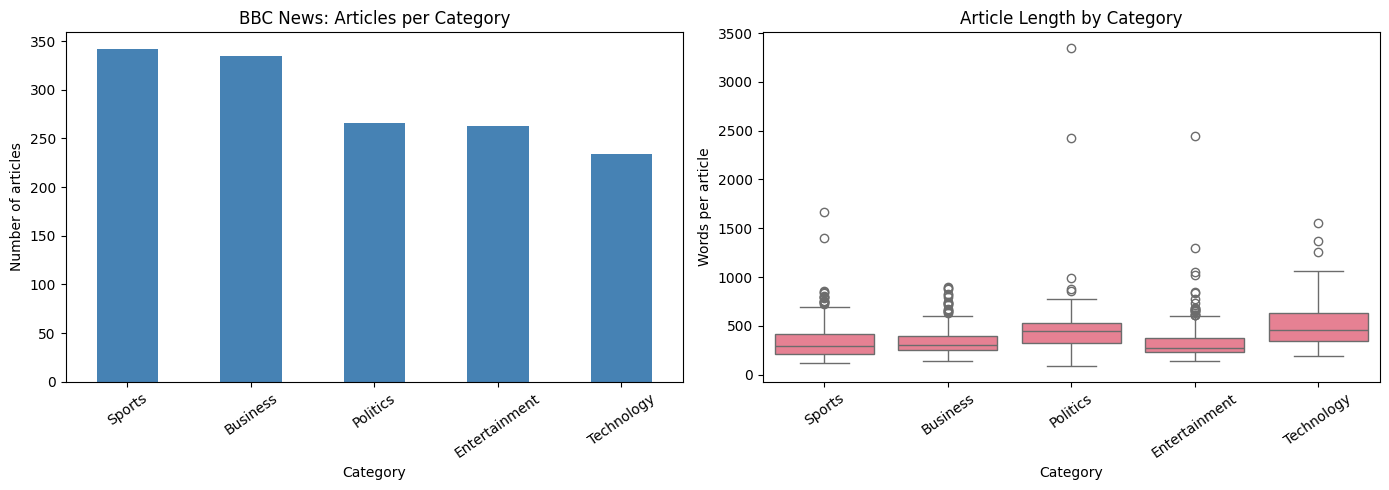

,count,mean,median,min,max
category,,,,,
Business,335,334.3,304.0,145,902
Entertainment,263,335.4,271.0,144,2448
Politics,266,451.6,445.0,90,3345
Sports,342,336.9,296.5,116,1671
Technology,234,509.2,461.5,188,1549


In [ ]:
# Basic dataset exploration
from pathlib import Path

# Use the cleaned dataset in the remaining starter-notebook cells.
df = df_clean.copy()

# Create a folder for figures we will later include on GitHub.
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Count articles in each category, from largest to smallest.
category_counts = df["category"].value_counts()

# Display counts and percentages to assess category balance.
category_summary = pd.DataFrame({
    "articles": category_counts,
    "percent": (category_counts / len(df) * 100).round(1)
})
display(category_summary)

# Create two plots: category sizes and article-length distributions.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Show how many articles belong to each category.
category_counts.plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("BBC News: Articles per Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Number of articles")
axes[0].tick_params(axis="x", rotation=35)

# Compare article lengths across categories.
# The boxes show the middle 50%; isolated points show unusual lengths.
sns.boxplot(
    data=df,
    x="category",
    y="word_count",
    order=category_counts.index,
    ax=axes[1]
)
axes[1].set_title("Article Length by Category")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Words per article")
axes[1].tick_params(axis="x", rotation=35)

# Save the figure before displaying it for the project documentation.
plt.tight_layout()
fig.savefig(output_dir / "dataset_overview.png", dpi=150, bbox_inches="tight")
plt.show()

# Compare typical article lengths numerically.
# The median is less affected by extremely long articles than the mean.
display(
    df.groupby("category")["word_count"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(1)
)

After removing 50 duplicate articles, the dataset contains 1,440 articles across five categories. Sports is the largest category (23.8%), while Technology is the smallest (16.2%). Technology articles have the highest median length at 461.5 words. These differences suggest that processing time may vary by category. They describe this dataset and should not be generalized to all news coverage.

## 🧹 Text Preprocessing Pipeline

### 🎯 Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [ ]:
# Initialize preprocessing tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """
    Comprehensive text cleaning function

    💡 TIP: This function should handle:
    - HTML tags and entities
    - URLs and email addresses
    - Special characters and numbers
    - Extra whitespace
    """
    if pd.isna(text):
        return ""

    # Convert to string and lowercase
    text = str(text).lower()

    # 🚀 YOUR CODE HERE: Implement text cleaning
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove special characters and digits (keep only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """
    Complete preprocessing pipeline

    💡 TIP: This function should:
    - Clean the text
    - Tokenize into words
    - Remove stop words (optional)
    - Lemmatize words (optional)
    - Return processed text
    """
    # Clean text
    text = clean_text(text)

    if not text:
        return ""

    # 🚀 YOUR CODE HERE: Implement tokenization and preprocessing
    # Tokenize
    tokens = word_tokenize(text)

    # Remove stop words if requested
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Lemmatize if requested
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Filter out very short words
    tokens = [token for token in tokens if len(token) > 2]

    return ' '.join(tokens)

# Test the preprocessing function
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
print("Original text:")
print(sample_text)
print("\nCleaned text:")
print(clean_text(sample_text))
print("\nFully preprocessed text:")
print(preprocess_text(sample_text))

Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Fully preprocessed text:
apple inc announced record quarterly earnings today visit info technews


In [ ]:
# BBC provides the headline and article together in the content column.
# Preserve that text for sentiment, named entities, and grammar analysis.
df["full_text"] = df["content"]

# Create a lightly cleaned version for comparison.
df["content_clean"] = df["content"].apply(clean_text)

# Create the tokenized, stop-word-filtered, lemmatized version.
# We will use this version for TF-IDF classification features.
print("Preprocessing articles...")
df["full_text_processed"] = df["full_text"].apply(preprocess_text)

# Keep this column name available for other starter-notebook sections.
df["content_processed"] = df["full_text_processed"]

# Check that preprocessing has not left any articles empty.
empty_count = df["full_text_processed"].str.strip().eq("").sum()
print("Articles with empty processed text:", empty_count)
assert empty_count == 0, "Inspect articles that became empty."

# Compare word counts before and after preprocessing.
df["processed_word_count"] = (
    df["full_text_processed"].str.split().str.len()
)

print("Articles processed:", len(df))
print("Average original words:", round(df["word_count"].mean(), 1))
print("Average processed words:", round(df["processed_word_count"].mean(), 1))

# Display three examples so we can inspect what changed.
for i in range(3):
    print(f"\nExample {i + 1}")
    print("Original:", df.iloc[i]["full_text"][:300])
    print("Processed:", df.iloc[i]["full_text_processed"][:300])

# Save the processed dataset so we can reuse the results.
df.to_csv("newsbot_processed.csv", index=False)

Preprocessing articles...
Articles with empty processed text: 0
Articles processed: 1440
Average original words: 385.2
Average processed words: 207.1

Example 1
Original: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at th
Processed: worldcom exboss launch defence lawyer defending former worldcom chief bernie ebbers battery fraud charge called company whistleblower first witness cynthia cooper worldcom exhead internal accounting alerted director irregular accounting practice telecom giant warning led collapse firm following disc

Example 2
Original: german business confidence slides german business confidence fell in february knocking hopes of a speedy recovery in europe s largest economy.  munich-based research institute ifo said that its c

## 📊 Feature Extraction and Statistical Analysis

### 🎯 TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [ ]:
# Split the cleaned articles into training (80%) and test (20%) sets.
# Stratification preserves approximately the same category proportions.
# A fixed random seed makes the split reproducible.
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["category"]
)

# Reset row indexes so later feature and label comparisons stay aligned.
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Store category labels separately from the text features.
y_train = train_df["category"]
y_test = test_df["category"]

# Configure our initial TF-IDF baseline.
# We will compare parameter settings later using training data only.
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,     # Limit vocabulary size to control memory use.
    ngram_range=(1, 2),    # Include single words and two-word sequences.
    min_df=2,             # Require a term to occur in at least two articles.
    max_df=0.8             # Exclude terms in over 80% of training articles.
)

# Learn vocabulary and IDF weights using ONLY training articles.
X_train_tfidf = tfidf_vectorizer.fit_transform(
    train_df["full_text_processed"]
)

# Apply the existing vocabulary and weights to the held-out test articles.
# Do not fit the vectorizer again on the test set.
X_test_tfidf = tfidf_vectorizer.transform(
    test_df["full_text_processed"]
)

# Retrieve the words and phrases represented by the feature columns.
feature_names = tfidf_vectorizer.get_feature_names_out()

# Keep features in sparse format: store nonzero values efficiently.
# Most articles contain only a small fraction of the full vocabulary.
print("Training feature shape:", X_train_tfidf.shape)
print("Test feature shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(feature_names))

# Verify that an identical article does not appear in both sets.
assert set(train_df["content"]).isdisjoint(set(test_df["content"]))

# Show the category distribution in each split.
display(pd.DataFrame({
    "training": y_train.value_counts(),
    "test": y_test.value_counts()
}))

Training feature shape: (1152, 5000)
Test feature shape: (288, 5000)
Vocabulary size: 5000


,training,test
category,,
Business,268,67
Entertainment,210,53
Politics,213,53
Sports,274,68
Technology,187,47


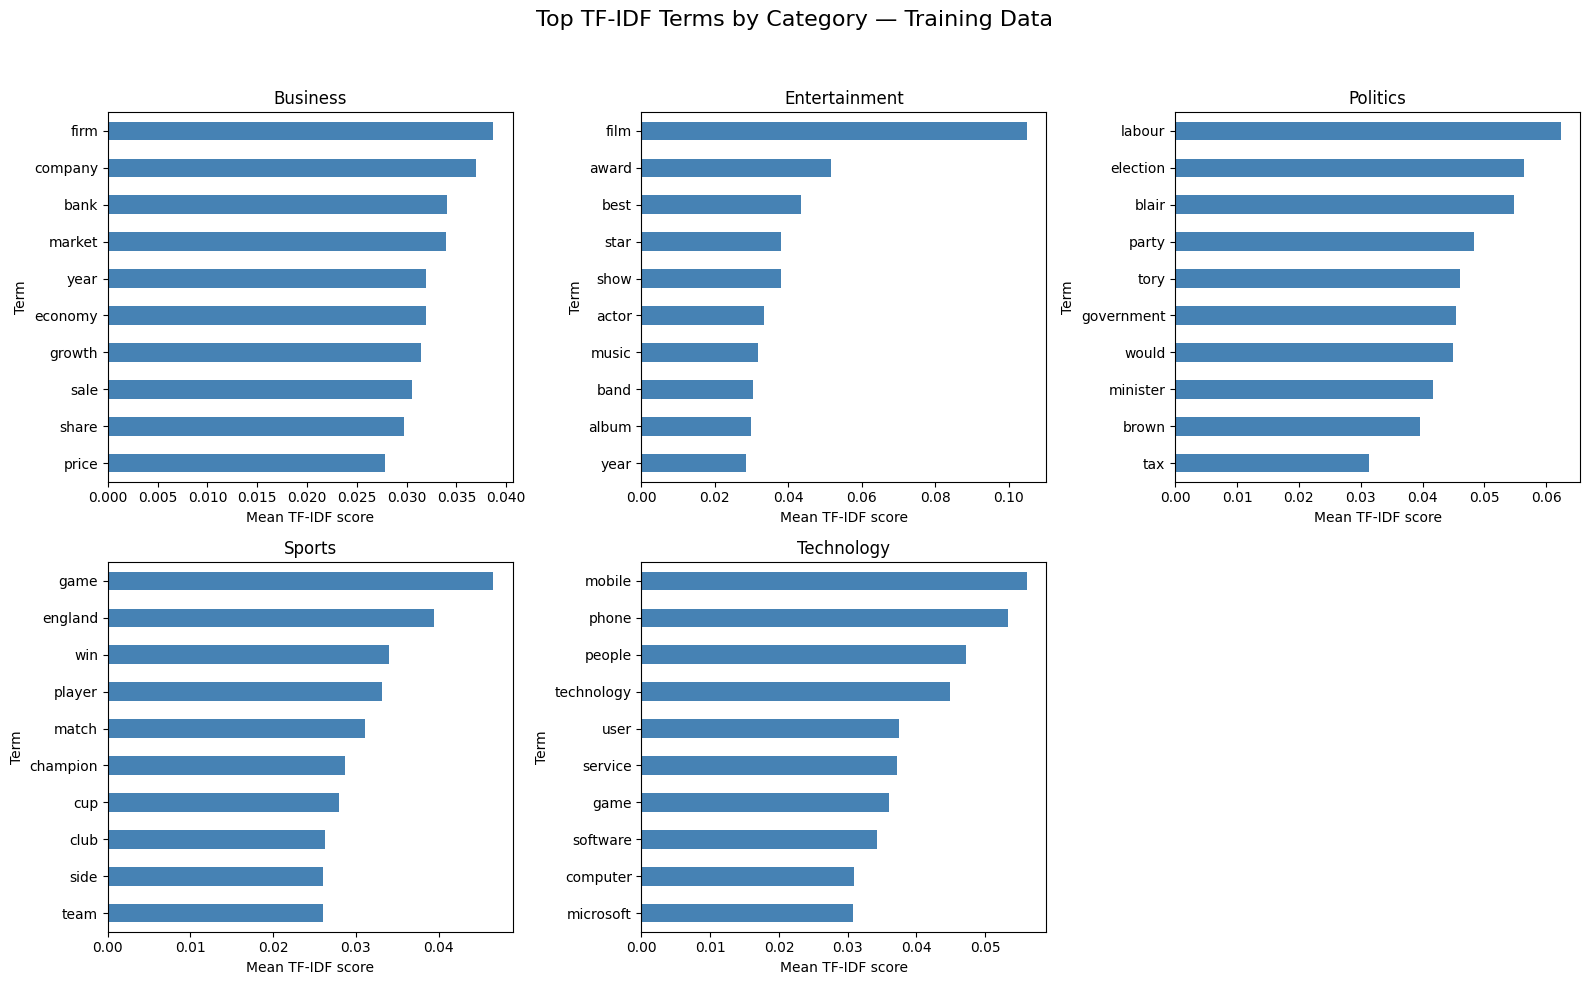

,category,term,mean_tfidf
0,Business,firm,0.038698
1,Business,company,0.036994
2,Business,bank,0.034070
3,Business,market,0.033938
4,Business,year,0.031944
5,Business,economy,0.031935
6,Business,growth,0.031483
7,Business,sale,0.030514
8,Business,share,0.029714
9,Business,price,0.027804


In [ ]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """Return terms with the highest average TF-IDF in a training category."""

    # Select training articles belonging to this category.
    category_mask = train_df["category"].eq(category).to_numpy()

    # Average each term's score across those articles.
    # Convert only the small average-score vector, not the entire matrix.
    mean_scores = np.asarray(
        X_train_tfidf[category_mask].mean(axis=0)
    ).ravel()

    # Attach term names and return the highest-scoring terms.
    return pd.Series(
        mean_scores, index=feature_names
    ).nlargest(n_terms)


# Create one chart per category and collect results for export.
categories = sorted(train_df["category"].unique())
category_terms = {}
term_tables = []

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for ax, category in zip(axes, categories):
    # Find the ten highest-scoring terms for this category.
    top_terms = get_top_tfidf_terms(category)
    category_terms[category] = top_terms

    # Sort ascending so the highest score appears at the top.
    top_terms.sort_values().plot.barh(ax=ax, color="steelblue")
    ax.set_title(category)
    ax.set_xlabel("Mean TF-IDF score")
    ax.set_ylabel("Term")

    # Store the numerical results alongside the visualization.
    term_tables.append(pd.DataFrame({
        "category": category,
        "term": top_terms.index,
        "mean_tfidf": top_terms.values
    }))

# Hide the unused sixth panel because BBC has five categories.
for ax in axes[len(categories):]:
    ax.set_visible(False)

# Save the chart for the GitHub project.
fig.suptitle("Top TF-IDF Terms by Category — Training Data", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(
    output_dir / "tfidf_terms_by_category.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Save and display the table so our findings can be checked.
top_terms_df = pd.concat(term_tables, ignore_index=True)
top_terms_df.to_csv(output_dir / "tfidf_top_terms.csv", index=False)
display(top_terms_df)

## 🏷️ Part-of-Speech Analysis

### 🎯 Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [ ]:
# Process the original article text to preserve grammatical context.
# Batch processing is more efficient than calling spaCy separately
# for every article. Cache the documents for syntax and NER analysis.
print("Processing articles with spaCy...")
docs = list(nlp.pipe(df["full_text"], batch_size=32))

# Collect grammatical proportions for each article.
pos_results = []

for article_id, category, doc in zip(
    df["article_id"], df["category"], docs
):
    # Exclude whitespace and punctuation from the denominator.
    tokens = [
        token for token in doc
        if not token.is_space and not token.is_punct
    ]

    # Count spaCy's broad POS tags, such as NOUN, VERB, and ADJ.
    counts = Counter(token.pos_ for token in tokens)
    total_tokens = len(tokens)

    # Use proportions so long and short articles can be compared.
    proportions = {
        tag: count / total_tokens
        for tag, count in counts.items()
    } if total_tokens else {}

    # Attach identifiers so we can group results by category.
    proportions["article_id"] = article_id
    proportions["category"] = category
    pos_results.append(proportions)

# A missing tag means that article had zero tokens of that type.
pos_df = pd.DataFrame(pos_results).fillna(0)

# Save the results for documentation and later analysis.
pos_df.to_csv(output_dir / "pos_article_proportions.csv", index=False)

print("Articles analyzed:", len(pos_df))
display(pos_df.head())

Processing articles with spaCy...
Articles analyzed: 1440


,PROPN,NOUN,VERB,ADJ,ADP,DET,AUX,PRON,PART,NUM,SYM,CCONJ,SCONJ,ADV,article_id,category,X,INTJ,PUNCT
0,0.137705,0.272131,0.134426,0.055738,0.118033,0.072131,0.042623,0.039344,0.036066,0.022951,0.009836,0.019672,0.019672,0.019672,1833,Business,0.0,0.0,0.0
1,0.070552,0.260736,0.119632,0.098160,0.113497,0.088957,0.064417,0.021472,0.021472,0.033742,0.000000,0.030675,0.033742,0.042945,154,Business,0.0,0.0,0.0
2,0.063953,0.228682,0.104651,0.081395,0.129845,0.094961,0.073643,0.052326,0.017442,0.062016,0.000000,0.029070,0.021318,0.040698,1101,Business,0.0,0.0,0.0
3,0.033123,0.249211,0.149842,0.093060,0.115142,0.063091,0.061514,0.072555,0.033123,0.018927,0.000000,0.022082,0.028391,0.059937,1976,Technology,0.0,0.0,0.0
4,0.064690,0.264151,0.110512,0.088949,0.129380,0.102426,0.059299,0.048518,0.013477,0.045822,0.024259,0.010782,0.008086,0.029650,917,Business,0.0,0.0,0.0


,NOUN,PROPN,VERB,AUX,ADJ,ADV,PRON,NUM
category,,,,,,,,
Business,25.28,8.23,12.44,5.47,8.00,3.07,3.93,3.89
Entertainment,25.01,9.94,12.22,5.20,7.42,2.94,5.60,3.36
Politics,23.38,8.02,13.68,6.95,7.55,3.07,6.21,1.77
Sports,20.82,10.60,12.83,5.88,7.11,3.71,7.77,3.29
Technology,26.12,4.98,13.45,6.37,8.35,3.80,5.58,2.48


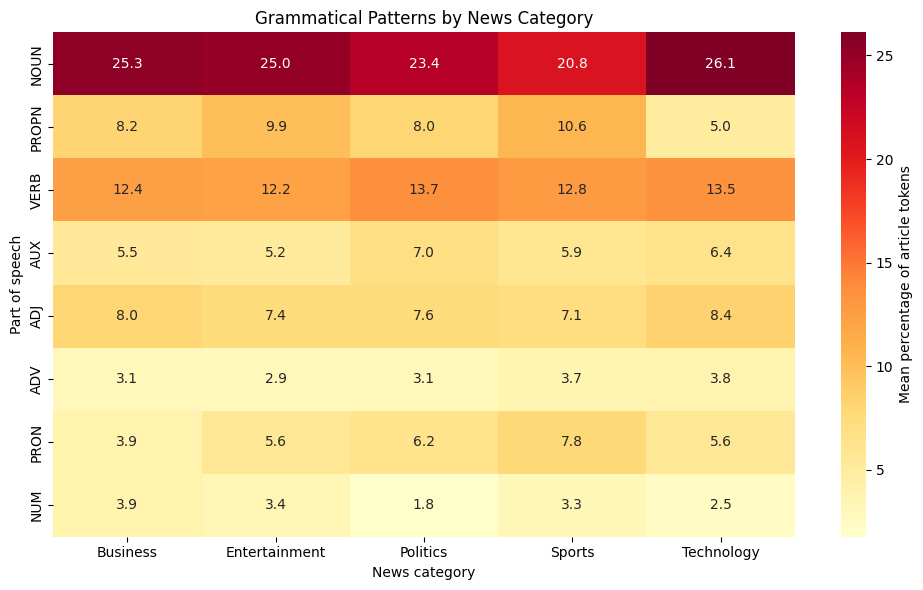

PROPN: Sports has the highest mean (10.60%).
VERB: Politics has the highest mean (13.68%).
ADJ: Technology has the highest mean (8.35%).
NUM: Business has the highest mean (3.89%).


In [ ]:
# Analyze POS patterns by category
# Select the grammatical categories we want to compare.
# These are spaCy's tag names, which differ from the starter's NLTK tags.
major_pos = ["NOUN", "PROPN", "VERB", "AUX", "ADJ", "ADV", "PRON", "NUM"]
available_pos = [tag for tag in major_pos if tag in pos_df.columns]

# Average article-level proportions within each news category.
# Selecting only POS columns prevents us from averaging article IDs.
# Each article contributes equally, regardless of its length.
pos_by_category = (
    pos_df.groupby("category")[available_pos].mean()
)

# Convert proportions to percentages for easier interpretation.
pos_percent = pos_by_category * 100
display(pos_percent.round(2))

# Plot grammatical patterns across the five news categories.
plt.figure(figsize=(10, 6))
sns.heatmap(
    pos_percent.T,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Mean percentage of article tokens"}
)
plt.title("Grammatical Patterns by News Category")
plt.xlabel("News category")
plt.ylabel("Part of speech")

# Save the chart and numerical results for the GitHub project.
plt.tight_layout()
plt.savefig(
    output_dir / "pos_patterns_by_category.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

pos_percent.to_csv(output_dir / "pos_category_percentages.csv")

# Identify the highest category for each selected grammatical feature.
# These are descriptive differences, not tests of statistical significance.
for tag in ["PROPN", "VERB", "ADJ", "NUM"]:
    if tag in pos_percent.columns:
        highest_category = pos_percent[tag].idxmax()
        highest_value = pos_percent.loc[highest_category, tag]
        print(f"{tag}: {highest_category} has the highest mean ({highest_value:.2f}%).")

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [ ]:
# Reuse the cached spaCy documents instead of processing articles again.
assert len(docs) == len(df), "Re-run the spaCy processing cell first."

syntax_rows = []
dependency_rows = []

for article_id, category, doc in zip(
    df["article_id"], df["category"], docs
):
    # Collect sentences and count meaningful tokens in each sentence.
    sentences = list(doc.sents)
    sentence_lengths = [
        sum(not token.is_space and not token.is_punct for token in sentence)
        for sentence in sentences
    ]

    # Use the same token definition as our POS analysis.
    tokens = [
        token for token in doc
        if not token.is_space and not token.is_punct
    ]
    token_count = len(tokens)

    # Count grammatical relationships assigned by the dependency parser.
    dep_counts = Counter(token.dep_ for token in tokens)

    # Record numerical features describing sentence structure.
    # Clause counts are approximate indicators, not a complete measure
    # of writing complexity or quality.
    syntax_rows.append({
        "article_id": article_id,
        "category": category,
        "sentence_count": len(sentences),
        "mean_sentence_length": (
            np.mean(sentence_lengths) if sentence_lengths else 0
        ),
        "noun_phrases_per_100_tokens": (
            100 * len(list(doc.noun_chunks)) / max(token_count, 1)
        ),
        "subordinate_clauses_per_100_tokens": (
            100 * sum(
                dep_counts[tag] for tag in ["advcl", "ccomp", "xcomp", "relcl"]
            ) / max(token_count, 1)
        )
    })

    # Normalize dependency counts so article length does not dominate.
    dependency_rows.append({
        "article_id": article_id,
        "category": category,
        **{
            tag: count / max(token_count, 1)
            for tag, count in dep_counts.items()
        }
    })

# Create tables for article-level features and dependency proportions.
syntax_df = pd.DataFrame(syntax_rows)
dependency_df = pd.DataFrame(dependency_rows).fillna(0)

# Compare average structural features across categories.
syntax_features = [
    "mean_sentence_length",
    "noun_phrases_per_100_tokens",
    "subordinate_clauses_per_100_tokens"
]
syntax_summary = syntax_df.groupby("category")[syntax_features].mean()

# Save results for the report and potential classification experiments.
syntax_df.to_csv(output_dir / "syntax_article_features.csv", index=False)
syntax_summary.to_csv(output_dir / "syntax_category_summary.csv")
dependency_df.to_csv(output_dir / "dependency_proportions.csv", index=False)

print("Articles analyzed:", len(syntax_df))
display(syntax_summary.round(2))

Articles analyzed: 1440


,mean_sentence_length,noun_phrases_per_100_tokens,subordinate_clauses_per_100_tokens
category,,,
Business,22.02,25.50,5.75
Entertainment,21.65,26.09,5.45
Politics,22.45,26.70,7.41
Sports,19.66,26.45,6.08
Technology,21.81,26.78,6.78


In [ ]:
# Visualize dependency parsing for a sample sentence
from spacy import displacy

def extract_svo(doc):
    """Find simple active-voice subject–verb–object relationships."""
    relationships = []

    # Map noun-phrase head tokens to their complete phrases.
    # This lets us return "the company" instead of only "company".
    noun_phrases = {
        chunk.root.i: chunk.text for chunk in doc.noun_chunks
    }

    for verb in doc:
        if verb.pos_ != "VERB":
            continue

        # Match subjects and direct objects attached to the SAME verb.
        subjects = [
            child for child in verb.children if child.dep_ == "nsubj"
        ]
        objects = [
            child for child in verb.children if child.dep_ == "dobj"
        ]

        # Flag direct negation so "did not acquire" is not treated
        # as an ordinary affirmative acquisition.
        negated = any(child.dep_ == "neg" for child in verb.children)

        for subject in subjects:
            for obj in objects:
                relationships.append({
                    "subject": noun_phrases.get(subject.i, subject.text),
                    "verb": verb.lemma_,
                    "object": noun_phrases.get(obj.i, obj.text),
                    "negated": negated,
                    "sentence": verb.sent.text.strip()
                })

    return relationships


# Use an explicitly fictional sentence to demonstrate the grammar.
# This is a teaching example, not a real news claim or training record.
demo_text = "The company acquired a startup."
demo_doc = nlp(demo_text)

print("Fictional demonstration sentence:", demo_text)
display(pd.DataFrame(extract_svo(demo_doc)))

# Display arrows showing grammatical relationships between words.
displacy.render(
    demo_doc,
    style="dep",
    jupyter=True,
    options={"compact": True, "distance": 100}
)

# Save the diagram as an HTML artifact for the project.
diagram_html = displacy.render(
    demo_doc,
    style="dep",
    page=True,
    jupyter=False,
    options={"compact": True, "distance": 100}
)
(output_dir / "dependency_demo.html").write_text(
    diagram_html, encoding="utf-8"
)

# Apply the same extraction rule to the cached news articles.
relationship_rows = []

for article_id, category, doc in zip(
    df["article_id"], df["category"], docs
):
    for relationship in extract_svo(doc):
        relationship_rows.append({
            "article_id": article_id,
            "category": category,
            **relationship
        })

# Specify columns so the table remains valid even if no matches exist.
relationships_df = pd.DataFrame(
    relationship_rows,
    columns=[
        "article_id", "category", "subject", "verb",
        "object", "negated", "sentence"
    ]
)

# Save extracted relationships and preview examples for manual review.
relationships_df.to_csv(
    output_dir / "subject_verb_object_relationships.csv", index=False
)
print("Candidate relationships extracted:", len(relationships_df))
display(relationships_df.head(10))

Fictional demonstration sentence: The company acquired a startup.


,subject,verb,object,negated,sentence
0,The company,acquire,a startup,False,The company acquired a startup.


Candidate relationships extracted: 16143


,article_id,category,subject,verb,object,negated,sentence
0,1833,Business,-,launch,defence lawyers,False,worldcom ex-boss launches defence lawyers defe...
1,1833,Business,boss,launch,defence lawyers,False,worldcom ex-boss launches defence lawyers defe...
2,1833,Business,s,alert,directors,False,worldcom s ex-head of internal accounting ale...
3,1833,Business,mr ebbers,orchestrate,a series,False,prosecution lawyers have argued that mr ebbers...
4,1833,Business,who,run,her own consulting business,False,but ms cooper who now runs her own consulting...
5,1833,Business,ms cooper,tell,a jury,False,but ms cooper who now runs her own consulting...
6,1833,Business,external auditors arthur andersen,approve,accounting,False,but ms cooper who now runs her own consulting...
7,1833,Business,andersen,give,a green light,False,she said andersen had given a green light to...
8,1833,Business,auditors,alert,him,True,mr ebber s lawyers have said he was unaware of...
9,1833,Business,mr ebbers,pass,technical questions,False,ms cooper also said that during shareholder me...


## 😊 Sentiment and Emotion Analysis

### 🎯 Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [ ]:
# Initialize sentiment analyzer
# Initialize VADER, a lexicon-and-rule-based sentiment analyzer.
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """Estimate positive, neutral, or negative tone using VADER."""

    # Handle missing or blank input explicitly.
    # "Unavailable" avoids treating absent text as genuinely neutral.
    if not isinstance(text, str) or not text.strip():
        return {
            "compound": np.nan,
            "pos": np.nan,
            "neu": np.nan,
            "neg": np.nan,
            "sentiment_label": "unavailable"
        }

    # Analyze the original text, retaining punctuation and negation.
    scores = sia.polarity_scores(text)

    # Apply VADER's standard compound-score thresholds.
    if scores["compound"] >= 0.05:
        scores["sentiment_label"] = "positive"
    elif scores["compound"] <= -0.05:
        scores["sentiment_label"] = "negative"
    else:
        scores["sentiment_label"] = "neutral"

    return scores


# Analyze each complete article.
# BBC does not provide a separate title column, so we omit title scoring.
sentiment_results = []

for article_id, category, text in zip(
    df["article_id"], df["category"], df["full_text"]
):
    scores = analyze_sentiment(text)

    # Preserve the column names used by the next analysis cell.
    sentiment_results.append({
        "article_id": article_id,
        "category": category,
        "full_sentiment": scores["compound"],
        "full_label": scores["sentiment_label"],
        "pos_score": scores["pos"],
        "neu_score": scores["neu"],
        "neg_score": scores["neg"]
    })

# Save article-level scores for analysis and documentation.
sentiment_df = pd.DataFrame(sentiment_results)
sentiment_df.to_csv(
    output_dir / "article_sentiment.csv", index=False
)

print("Articles analyzed:", len(sentiment_df))
print("\nSentiment label counts:")
print(sentiment_df["full_label"].value_counts())

display(
    sentiment_df[["article_id", "category", "full_sentiment", "full_label"]]
    .head(10)
)

Articles analyzed: 1440

Sentiment label counts:
full_label
positive    1013
negative     416
neutral       11
Name: count, dtype: int64


,article_id,category,full_sentiment,full_label
0,1833,Business,-0.9701,negative
1,154,Business,0.7623,positive
2,1101,Business,-0.9318,negative
3,1976,Technology,0.9554,positive
4,917,Business,-0.9486,negative
5,1582,Politics,0.9767,positive
6,651,Sports,0.9833,positive
7,1797,Entertainment,0.9805,positive
8,2034,Business,0.9959,positive
9,1866,Entertainment,-0.0253,neutral


Sentiment statistics by category:


full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
category                                                                   
Business              0.2381  0.8372 -0.9985  0.9995    0.0924    0.8371   
Entertainment         0.5900  0.6865 -0.9978  0.9999    0.1362    0.8093   
Politics              0.0541  0.8798 -0.9984  0.9999    0.0946    0.8183   
Sports                0.5492  0.7272 -0.9967  0.9996    0.1355    0.7938   
Technology            0.5330  0.7479 -0.9991  0.9993    0.0898    0.8598   

              neg_score  
                   mean  
category                 
Business         0.0705  
Entertainment    0.0545  
Politics         0.0871  
Sports           0.0707  
Technology       0.0504

Sentiment label percentages by category:


full_label,negative,neutral,positive
category,,,
Business,36.42,1.49,62.09
Entertainment,19.01,0.76,80.23
Politics,46.62,0.38,53.01
Sports,20.76,0.29,78.95
Technology,20.94,0.85,78.21


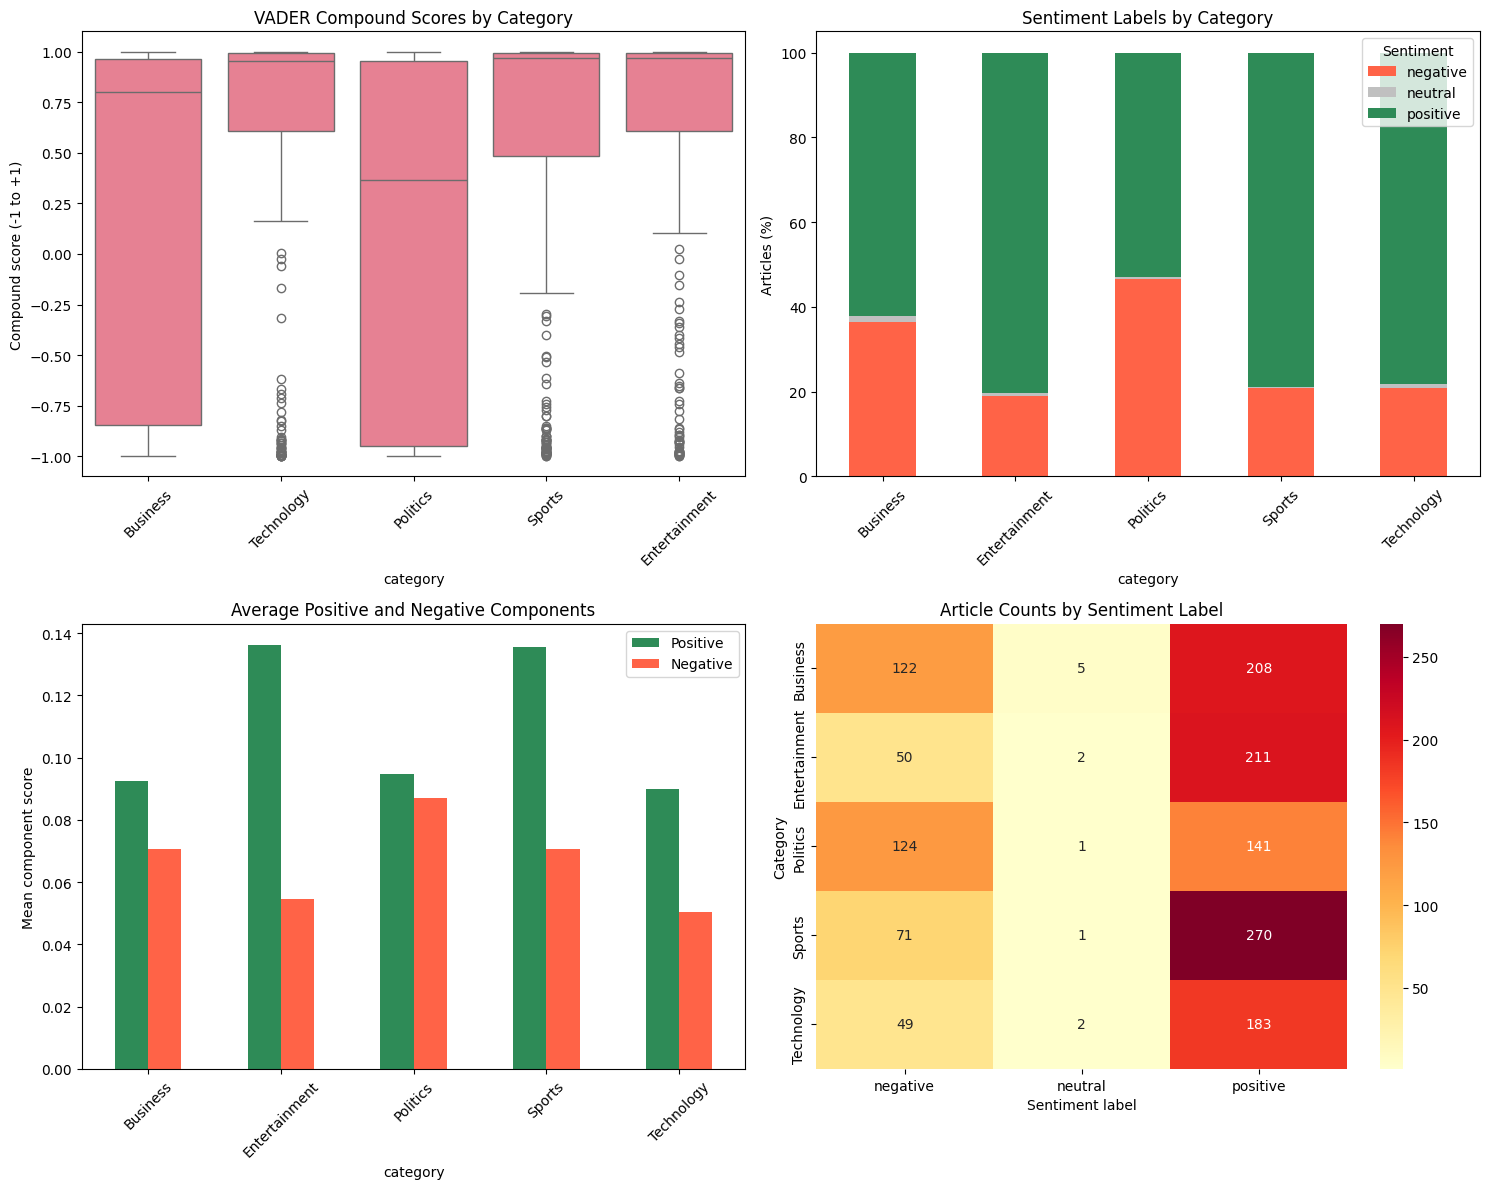

Sentiment charts and summary tables saved to outputs/.


In [ ]:
# Analyze sentiment patterns by category
# Summarize sentiment scores within each news category.
sentiment_by_category = sentiment_df.groupby("category").agg({
    "full_sentiment": ["mean", "std", "min", "max"],
    "pos_score": "mean",
    "neu_score": "mean",
    "neg_score": "mean"
})

print("Sentiment statistics by category:")
display(sentiment_by_category.round(4))

# Count positive, neutral, and negative articles in each category.
# Include all three labels even if one has no articles.
sentiment_dist = pd.crosstab(
    sentiment_df["category"],
    sentiment_df["full_label"]
).reindex(columns=["negative", "neutral", "positive"], fill_value=0)

# Convert counts into percentages so categories of different sizes
# can be compared fairly.
sentiment_dist_pct = (
    sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100
)

print("Sentiment label percentages by category:")
display(sentiment_dist_pct.round(2))

# Create four views of the sentiment results.
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Show the spread of compound scores within each category.
sns.boxplot(
    data=sentiment_df,
    x="category",
    y="full_sentiment",
    ax=axes[0, 0]
)
axes[0, 0].set_title("VADER Compound Scores by Category")
axes[0, 0].set_ylabel("Compound score (-1 to +1)")
axes[0, 0].tick_params(axis="x", rotation=45)

# 2. Compare the percentage of articles assigned each sentiment label.
sentiment_dist_pct.plot(
    kind="bar",
    stacked=True,
    color=["tomato", "silver", "seagreen"],
    ax=axes[0, 1]
)
axes[0, 1].set_title("Sentiment Labels by Category")
axes[0, 1].set_ylabel("Articles (%)")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].legend(title="Sentiment")

# 3. Compare average positive and negative component scores.
# These scores describe textual sentiment, not model confidence.
category_means = sentiment_df.groupby("category")[
    ["pos_score", "neg_score"]
].mean()

category_means.plot(
    kind="bar",
    color=["seagreen", "tomato"],
    ax=axes[1, 0]
)
axes[1, 0].set_title("Average Positive and Negative Components")
axes[1, 0].set_ylabel("Mean component score")
axes[1, 0].tick_params(axis="x", rotation=45)
axes[1, 0].legend(["Positive", "Negative"])

# 4. Show the actual article counts behind the percentages.
sns.heatmap(
    sentiment_dist,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Article Counts by Sentiment Label")
axes[1, 1].set_xlabel("Sentiment label")
axes[1, 1].set_ylabel("Category")

# Save the charts before displaying them.
plt.tight_layout()
fig.savefig(
    output_dir / "sentiment_by_category.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Save the numerical summaries for documentation and review.
sentiment_by_category.to_csv(
    output_dir / "sentiment_category_statistics.csv"
)
sentiment_dist_pct.to_csv(
    output_dir / "sentiment_category_percentages.csv"
)

print("Sentiment charts and summary tables saved to outputs/.")

## 🏷️ Text Classification System

### 🎯 Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [ ]:
# Prepare features for classification
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline

# Reuse our existing split; do not create a different test set.
X_train_text = train_df["full_text_processed"]
X_test_text = test_df["full_text_processed"]
y_train = train_df["category"]
y_test = test_df["category"]

# Divide the training data into three folds for model comparison.
# Each fold preserves approximately the same category proportions.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Compare the three algorithms suggested in the starter notebook.
# A linear SVM is a suitable baseline for sparse text features.
classifiers = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "SVM": SVC(kernel="linear", probability=True, random_state=42)
}

# Each pipeline learns its vocabulary inside each training fold.
# This prevents validation articles from influencing TF-IDF fitting.
model_pipelines = {
    name: Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            min_df=2,
            max_df=0.8
        )),
        ("classifier", classifier)
    ])
    for name, classifier in classifiers.items()
}

# Compare individual words against words plus two-word phrases.
# Also test whether reducing the influence of repeated words helps.
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__sublinear_tf": [False, True]
}

# Keep this first comparison focused on TF-IDF features.
# Multinomial Naive Bayes requires nonnegative inputs, so we should
# not directly append negative VADER compound scores.
print("Training articles:", len(X_train_text))
print("Held-out test articles:", len(X_test_text))
print("Models:", list(model_pipelines))
print("TF-IDF configurations per model: 4")
print("Ready for training; no models have been fitted in this cell.")

Training articles: 1152
Held-out test articles: 288
Models: ['Naive Bayes', 'Logistic Regression', 'SVM']
TF-IDF configurations per model: 4
Ready for training; no models have been fitted in this cell.


In [ ]:
# Train and evaluate multiple classifiers
from time import perf_counter

# Store fitted pipelines, search results, and comparison statistics.
trained_models = {}
search_results = {}
comparison_rows = []

for name, pipeline in model_pipelines.items():
    print(f"\nTraining and tuning {name}...")
    start_time = perf_counter()

    # Try each TF-IDF configuration using three-fold cross-validation.
    # Macro F1 gives every news category equal importance.
    # Accuracy is recorded as an additional metric.
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring={
            "macro_f1": "f1_macro",
            "accuracy": "accuracy"
        },
        refit="macro_f1",
        cv=cv,
        n_jobs=1,             # Limit parallel memory use on free Colab.
        error_score="raise"  # Show errors instead of silently skipping fits.
    )

    # Use only the training articles during tuning.
    # The pipeline fits TF-IDF separately inside each training fold.
    search.fit(X_train_text, y_train)

    # GridSearchCV refits the winning configuration on all training data.
    trained_models[name] = search.best_estimator_
    search_results[name] = search

    # Record scores for the configuration selected by macro F1.
    best_index = search.best_index_
    comparison_rows.append({
        "Model": name,
        "CV Macro F1": search.best_score_,
        "CV F1 Std": search.cv_results_[
            "std_test_macro_f1"
        ][best_index],
        "CV Accuracy": search.cv_results_[
            "mean_test_accuracy"
        ][best_index],
        "Training Seconds": perf_counter() - start_time,
        "Best Parameters": str(search.best_params_)
    })

    # Save all parameter-trial results for reproducibility.
    filename = name.lower().replace(" ", "_")
    pd.DataFrame(search.cv_results_).to_csv(
        output_dir / f"{filename}_tuning_results.csv",
        index=False
    )

    print(f"Best cross-validation macro F1: {search.best_score_:.4f}")
    print("Selected parameters:", search.best_params_)

# Rank algorithms using cross-validation performance, not test results.
comparison_df = (
    pd.DataFrame(comparison_rows)
    .sort_values("CV Macro F1", ascending=False)
    .reset_index(drop=True)
)

best_model_name = comparison_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

# Save and display the model comparison.
comparison_df.to_csv(output_dir / "model_comparison_cv.csv", index=False)
display(comparison_df.round(4))

print("\nSelected model:", best_model_name)
print("The held-out test set has not been evaluated yet.")


Training and tuning Naive Bayes...
Best cross-validation macro F1: 0.9685
Selected parameters: {'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}

Training and tuning Logistic Regression...
Best cross-validation macro F1: 0.9749
Selected parameters: {'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': True}

Training and tuning SVM...
Best cross-validation macro F1: 0.9746
Selected parameters: {'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': True}


,Model,CV Macro F1,CV F1 Std,CV Accuracy,Training Seconds,Best Parameters
0,Logistic Regression,0.9749,0.0067,0.9757,15.9300,"{'tfidf__ngram_range': (1, 1), 'tfidf__subline..."
1,SVM,0.9746,0.0088,0.9757,121.6218,"{'tfidf__ngram_range': (1, 1), 'tfidf__subline..."
2,Naive Bayes,0.9685,0.0068,0.9696,18.9033,"{'tfidf__ngram_range': (1, 2), 'tfidf__subline..."



Selected model: Logistic Regression
The held-out test set has not been evaluated yet.


Selected model: Logistic Regression
Test accuracy: 0.9618
Test macro F1: 0.9598

Classification report:
               precision    recall  f1-score   support

     Business     0.9429    0.9851    0.9635        67
Entertainment     0.9811    0.9811    0.9811        53
     Politics     0.9804    0.9434    0.9615        53
       Sports     0.9444    1.0000    0.9714        68
   Technology     0.9762    0.8723    0.9213        47

     accuracy                         0.9618       288
    macro avg     0.9650    0.9564    0.9598       288
 weighted avg     0.9626    0.9618    0.9614       288



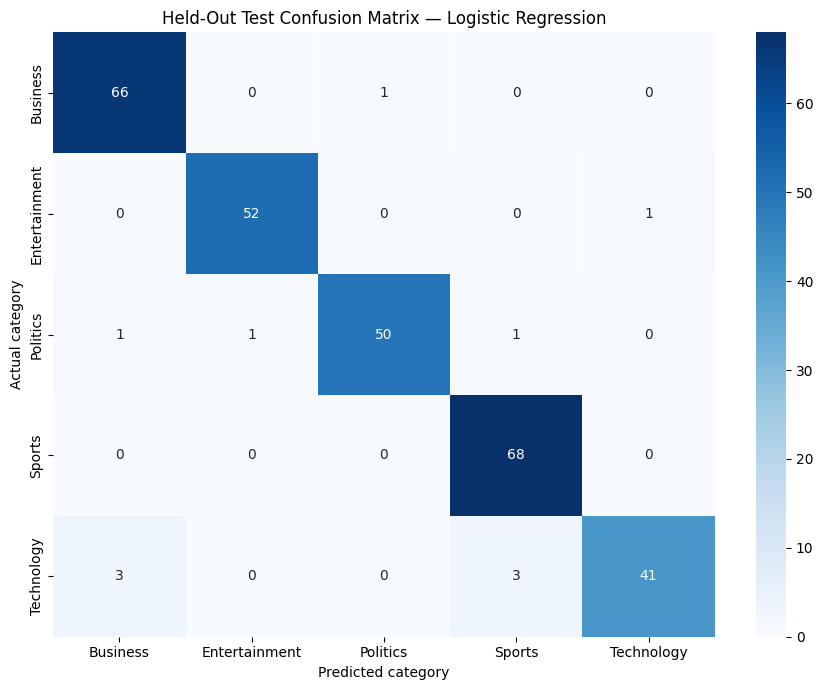


Misclassified articles: 11


,article_id,category,predicted_category,excerpt
1,20,Technology,Business,games maker fights for survival one of britain...
17,1381,Business,Politics,world leaders gather to face uncertainty more ...
53,196,Politics,Entertainment,mp s shock at long lost daughter labour mp ste...
59,1725,Technology,Sports,players sought for $1m prize uk gamers are get...
66,739,Technology,Business,us duo in first spam conviction a brother and ...
74,848,Entertainment,Technology,bbc should allow more scrutiny mps have urge...
76,778,Politics,Business,eu fraud clampdown urged eu member states are ...
115,2205,Technology,Business,argonaut founder rebuilds empire jez san the ...
130,647,Technology,Sports,gritty return for prince of persia still baski...
143,1582,Politics,Sports,howard truanted to play snooker conservative...



Top model features by category:


,category,term,coefficient
0,Business,firm,1.905472
1,Business,company,1.815663
2,Business,bank,1.617851
3,Business,market,1.434650
4,Business,economy,1.336637
5,Business,share,1.329186
6,Business,economic,1.278026
7,Business,investment,1.236964
8,Business,price,1.198361
9,Business,profit,1.176427


In [ ]:
# Detailed evaluation of the best model
from sklearn.metrics import f1_score

# Evaluate the model already selected by cross-validation.
# The fitted pipeline applies its own TF-IDF vocabulary automatically.
best_predictions = best_model.predict(X_test_text)

# Report overall accuracy and macro F1 on the held-out articles.
test_accuracy = accuracy_score(y_test, best_predictions)
test_macro_f1 = f1_score(y_test, best_predictions, average="macro")

print("Selected model:", best_model_name)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro F1: {test_macro_f1:.4f}")

# Show precision, recall, and F1 separately for every category.
# Support is the number of actual test articles in each category.
print("\nClassification report:")
print(classification_report(
    y_test, best_predictions, digits=4, zero_division=0
))

report_df = pd.DataFrame(
    classification_report(
        y_test, best_predictions, output_dict=True, zero_division=0
    )
).T
report_df.to_csv(output_dir / "test_classification_report.csv")

# Use the model's class order consistently for both matrix axes.
classes = best_model.classes_
cm = confusion_matrix(y_test, best_predictions, labels=classes)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)
plt.title(f"Held-Out Test Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted category")
plt.ylabel("Actual category")
plt.tight_layout()
plt.savefig(
    output_dir / "test_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Save predictions and identify mistakes for qualitative review.
test_results = test_df[["article_id", "category", "content"]].copy()
test_results["predicted_category"] = best_predictions
test_results["correct"] = (
    test_results["category"] == test_results["predicted_category"]
)
test_results.to_csv(output_dir / "test_predictions.csv", index=False)

errors_df = test_results.loc[~test_results["correct"]].copy()
print("\nMisclassified articles:", len(errors_df))

# Display short excerpts so we can investigate ambiguous topics.
display(
    errors_df.assign(excerpt=errors_df["content"].str[:300])[
        ["article_id", "category", "predicted_category", "excerpt"]
    ].head(10)
)

# Explain the selected Logistic Regression model using its coefficients.
# Retrieve its vocabulary: it may differ from our earlier TF-IDF baseline.
if best_model_name == "Logistic Regression":
    model_terms = best_model.named_steps["tfidf"].get_feature_names_out()
    classifier = best_model.named_steps["classifier"]
    feature_rows = []

    for category, coefficients in zip(
        classifier.classes_, classifier.coef_
    ):
        # Larger positive coefficients support this category's model score.
        # They describe model associations, not causal relationships.
        top_indices = np.argsort(coefficients)[-10:][::-1]

        for index in top_indices:
            feature_rows.append({
                "category": category,
                "term": model_terms[index],
                "coefficient": coefficients[index]
            })

    feature_importance_df = pd.DataFrame(feature_rows)
    feature_importance_df.to_csv(
        output_dir / "classifier_top_features.csv", index=False
    )
    print("\nTop model features by category:")
    display(feature_importance_df)

## 🔍 Named Entity Recognition

### 🎯 Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [ ]:
# Focus on the five entity types required by the assignment.
required_entity_types = {"PERSON", "ORG", "GPE", "DATE", "MONEY"}

def entities_from_doc(doc):
    """Extract required entity types from an already processed document."""
    return [
        {
            "text": ent.text,
            "label": ent.label_,
            "start": ent.start_char,
            "end": ent.end_char,
            "description": spacy.explain(ent.label_)
        }
        for ent in doc.ents
        if ent.label_ in required_entity_types
    ]


def extract_entities(text):
    """Process a new article and return its named entities."""
    # Keep this function for the integrated NewsBot demonstration later.
    if not isinstance(text, str) or not text.strip():
        return []
    return entities_from_doc(nlp(text))


# Reuse cached documents to avoid processing the dataset again.
all_entities = []
article_entities = []

for article_id, category, doc in zip(
    df["article_id"], df["category"], docs
):
    entities = entities_from_doc(doc)

    # Keep article-level records, including articles with no entities.
    article_entities.append({
        "article_id": article_id,
        "category": category,
        "entities": entities,
        "entity_count": len(entities)
    })

    # Create one table row for each entity mention.
    for entity in entities:
        all_entities.append({
            **entity,
            "article_id": article_id,
            "category": category
        })

# Specify columns so an empty result still produces a usable table.
entities_df = pd.DataFrame(
    all_entities,
    columns=[
        "text", "label", "start", "end",
        "description", "article_id", "category"
    ]
)

# Standardize spacing and case for frequency counting.
# This does not resolve aliases such as "IBM" and its full name.
entities_df["normalized_text"] = (
    entities_df["text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Save extracted mentions for later analysis.
entities_df.to_csv(output_dir / "named_entity_mentions.csv", index=False)

print("Articles processed:", len(article_entities))
print("Entity mentions extracted:", len(entities_df))
print("\nMention counts by entity type:")
print(
    entities_df["label"].value_counts()
    .reindex(sorted(required_entity_types), fill_value=0)
)

# Preview results for manual inspection.
display(entities_df[["text", "label", "category"]].head(15))

Articles processed: 1440
Entity mentions extracted: 27756

Mention counts by entity type:
label
DATE      8523
GPE       5433
MONEY     1710
ORG       4288
PERSON    7802
Name: count, dtype: int64


,text,label,category
0,cynthia cooper,PERSON,Business
1,us,GPE,Business
2,2002,DATE,Business
3,5.7bn,MONEY,Business
4,new york,GPE,Business
5,wednesday,DATE,Business
6,arthur andersen,PERSON,Business
7,early 2001 and,DATE,Business
8,2002,DATE,Business
9,scott sullivan,PERSON,Business


Average entity mentions per article:


label,DATE,GPE,MONEY,ORG,PERSON
category,,,,,
Business,7.16,4.61,2.70,4.16,2.91
Entertainment,6.36,2.94,1.30,2.40,6.82
Politics,4.97,3.51,0.83,2.20,7.08
Sports,5.75,4.33,0.13,1.97,7.32
Technology,4.98,3.00,0.84,4.30,2.76


Entities appearing in the most articles:


,normalized_text,label,article_count
0,us,GPE,297
1,uk,GPE,294
2,london,GPE,180
3,last year,DATE,173
4,britain,GPE,163
5,2004,DATE,161
6,2005,DATE,151
7,bbc,ORG,141
8,2003,DATE,138
9,this year,DATE,137


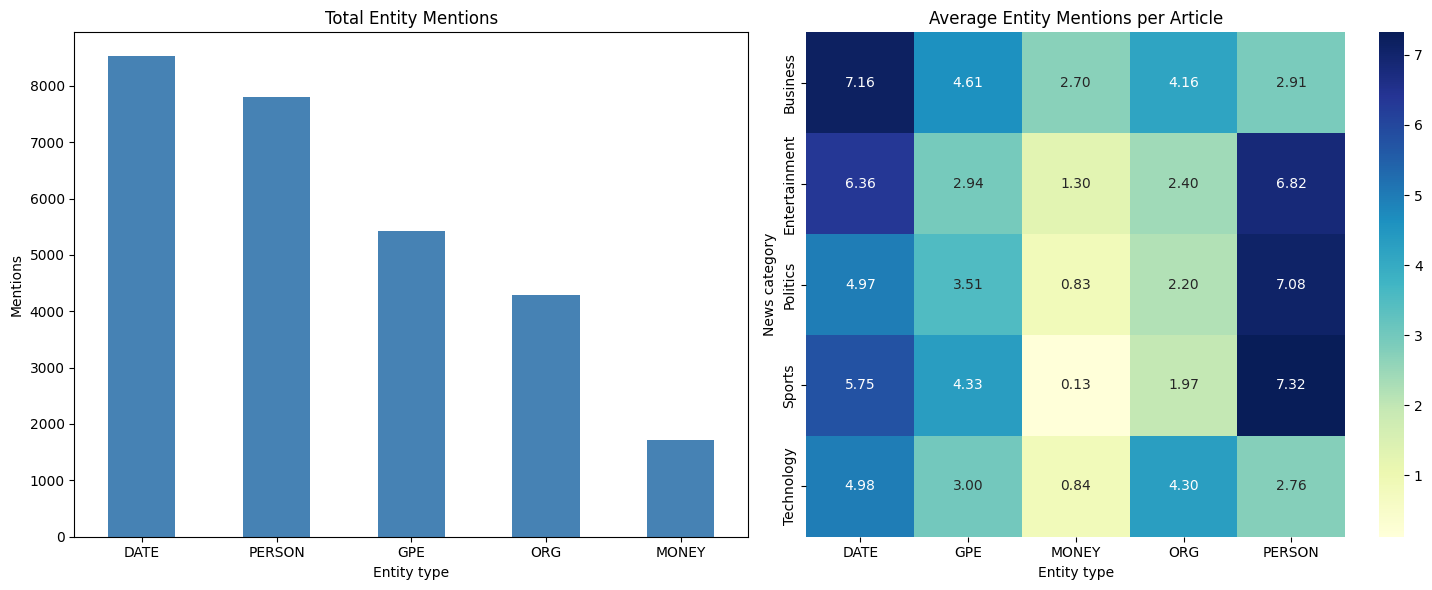

In [ ]:
# Analyze entity patterns
# Count entity mentions by news category and entity type.
entity_by_category = pd.crosstab(
    entities_df["category"], entities_df["label"]
).reindex(
    index=sorted(df["category"].unique()),
    columns=sorted(required_entity_types),
    fill_value=0
)

# Divide by the number of articles in each category.
# Include articles with zero mentions in the denominator.
article_counts = df.groupby("category").size()
entity_rates = entity_by_category.div(article_counts, axis=0)

print("Average entity mentions per article:")
display(entity_rates.round(2))

# Count how many different articles mention each entity.
# Repeating a name within one article counts only once here.
entity_article_counts = (
    entities_df.groupby(["normalized_text", "label"])["article_id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("article_count")
    .reset_index()
)

print("Entities appearing in the most articles:")
display(entity_article_counts.head(15))

# Show total mentions and category-normalized rates.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

entities_df["label"].value_counts().plot.bar(
    ax=axes[0], color="steelblue"
)
axes[0].set_title("Total Entity Mentions")
axes[0].set_xlabel("Entity type")
axes[0].set_ylabel("Mentions")
axes[0].tick_params(axis="x", rotation=0)

sns.heatmap(
    entity_rates,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    ax=axes[1]
)
axes[1].set_title("Average Entity Mentions per Article")
axes[1].set_xlabel("Entity type")
axes[1].set_ylabel("News category")

# Save the figure and supporting tables for the project.
plt.tight_layout()
fig.savefig(
    output_dir / "entity_patterns.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

entity_rates.to_csv(output_dir / "entity_rates_by_category.csv")
entity_article_counts.to_csv(
    output_dir / "entity_article_frequencies.csv", index=False
)

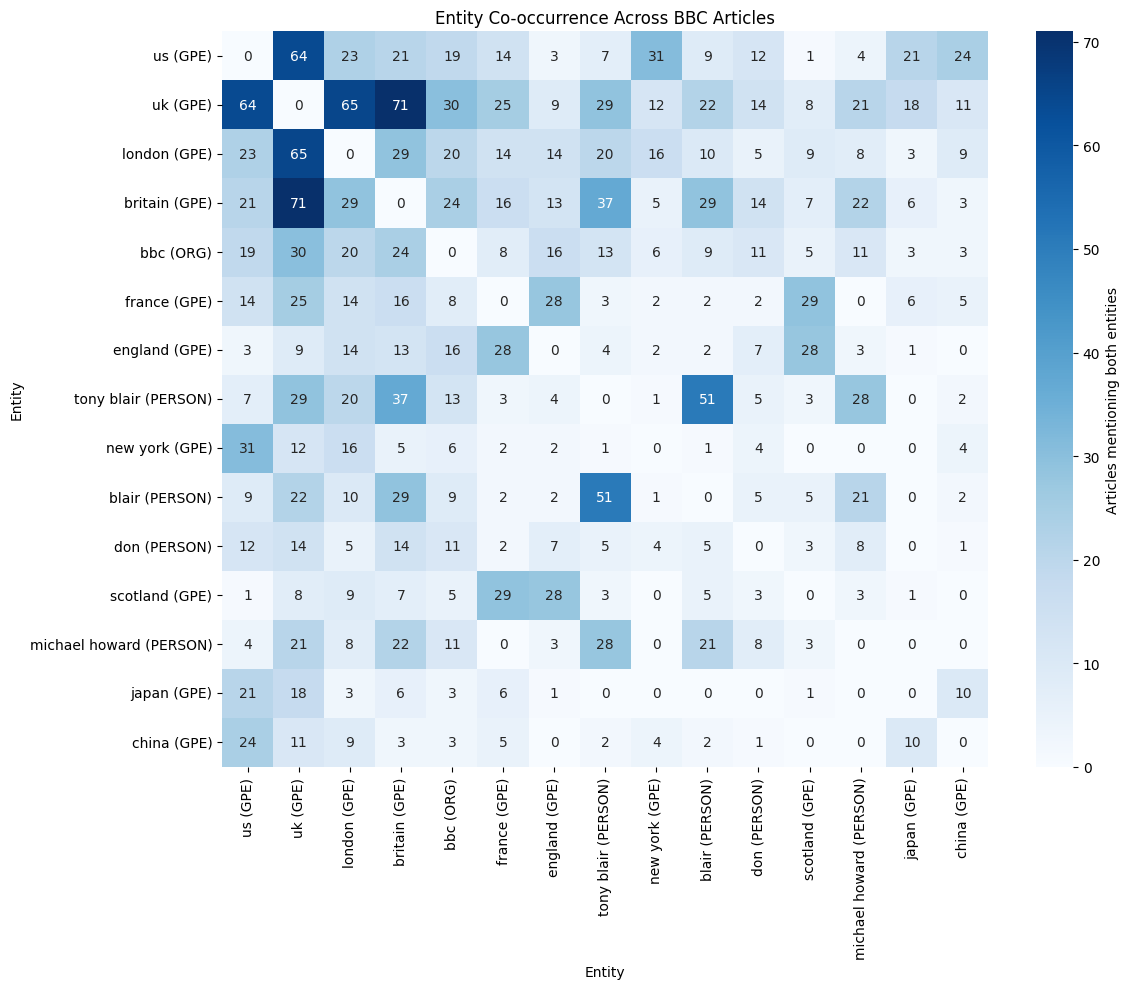

,entity_1,entity_2,shared_articles
15,uk (GPE),britain (GPE),71
14,uk (GPE),london (GPE),65
0,us (GPE),uk (GPE),64
76,tony blair (PERSON),blair (PERSON),51
42,britain (GPE),tony blair (PERSON),37
7,us (GPE),new york (GPE),31
16,uk (GPE),bbc (ORG),30
65,france (GPE),scotland (GPE),29
27,london (GPE),britain (GPE),29
19,uk (GPE),tony blair (PERSON),29


In [ ]:
# Focus the map on people, organizations, and places.
# Dates and monetary amounts remain in our earlier analyses.
map_entities = entities_df[
    entities_df["label"].isin(["PERSON", "ORG", "GPE"])
].copy()

# Include the entity type in each identifier to keep labels distinct.
map_entities["entity_key"] = (
    map_entities["normalized_text"] + " (" + map_entities["label"] + ")"
)

# Count each entity only once per article.
unique_mentions = map_entities.drop_duplicates(
    subset=["article_id", "entity_key"]
)

# Select the 15 entities appearing in the most distinct articles.
top_entities = (
    unique_mentions["entity_key"].value_counts().head(15).index
)

# Build an article-by-entity presence table.
# A value of 1 means the entity appeared somewhere in that article.
presence = pd.crosstab(
    unique_mentions["article_id"],
    unique_mentions["entity_key"]
).reindex(columns=top_entities, fill_value=0)

# Matrix multiplication counts articles containing each entity pair.
cooccurrence = presence.T.dot(presence)

# Hide self-counts so the chart emphasizes pairs of different entities.
np.fill_diagonal(cooccurrence.values, 0)

# Display the co-occurrence map.
plt.figure(figsize=(12, 10))
sns.heatmap(
    cooccurrence,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar_kws={"label": "Articles mentioning both entities"}
)
plt.title("Entity Co-occurrence Across BBC Articles")
plt.xlabel("Entity")
plt.ylabel("Entity")
plt.tight_layout()
plt.savefig(
    output_dir / "entity_cooccurrence.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Save the matrix and a ranked list of pairs.
cooccurrence.to_csv(output_dir / "entity_cooccurrence_matrix.csv")

pair_rows = []
for i, first_entity in enumerate(top_entities):
    for j in range(i + 1, len(top_entities)):
        second_entity = top_entities[j]
        count = int(cooccurrence.loc[first_entity, second_entity])

        if count > 0:
            pair_rows.append({
                "entity_1": first_entity,
                "entity_2": second_entity,
                "shared_articles": count
            })

entity_pairs_df = pd.DataFrame(
    pair_rows,
    columns=["entity_1", "entity_2", "shared_articles"]
).sort_values("shared_articles", ascending=False)

entity_pairs_df.to_csv(
    output_dir / "entity_cooccurrence_pairs.csv", index=False
)
display(entity_pairs_df.head(10))

Mean emotion-keyword matches per 1,000 alphabetic tokens:


,joy,sadness,anger,fear,surprise,trust
category,,,,,,
Business,0.12,0.04,0.05,0.34,0.18,0.46
Entertainment,0.45,0.06,0.17,0.25,0.30,0.07
Politics,0.20,0.05,0.17,0.84,0.08,0.72
Sports,0.65,0.06,0.14,0.14,0.14,0.40
Technology,0.15,0.03,0.08,0.19,0.13,0.13


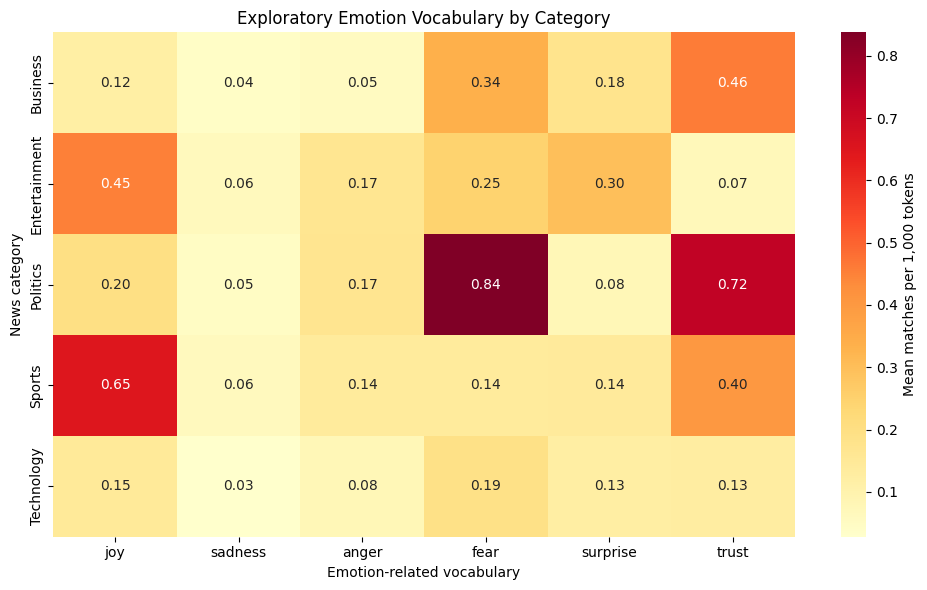

First article's matched vocabulary: {'joy': {}, 'sadness': {}, 'anger': {}, 'fear': {}, 'surprise': {}, 'trust': {}}


In [ ]:
# Define a small illustrative emotion lexicon for this project.
# These hand-selected words are an exploratory baseline, not a
# validated dictionary. Results depend strongly on word selection.
emotion_lexicon = {
    "joy": {"joy", "happy", "delight", "celebrate", "pleased", "thrilled"},
    "sadness": {"sad", "sadness", "grief", "mourn", "sorrow", "unhappy"},
    "anger": {"anger", "angry", "furious", "outrage", "rage", "resentment"},
    "fear": {"fear", "afraid", "terror", "panic", "anxiety", "frightened"},
    "surprise": {"surprise", "surprised", "unexpected", "astonish", "amaze"},
    "trust": {"trust", "confidence", "reliable", "credible", "faith"}
}

def analyze_emotion_cues(doc):
    """Count illustrative emotion keywords per 1,000 alphabetic tokens."""

    # Use lemmas so related forms can match a shared base word.
    # Preserve the original article for spaCy's contextual processing.
    lemmas = [token.lemma_.lower() for token in doc if token.is_alpha]
    counts = Counter(lemmas)

    # Keep matched words visible so a person can inspect the evidence.
    matches = {
        emotion: {
            word: counts[word] for word in sorted(words)
            if counts[word] > 0
        }
        for emotion, words in emotion_lexicon.items()
    }

    # Normalize counts to reduce the effect of article length.
    rates = {
        emotion: 1000 * sum(words.values()) / max(len(lemmas), 1)
        for emotion, words in matches.items()
    }
    return rates, matches


# Analyze cached documents without rerunning the spaCy pipeline.
emotion_rows = []

for article_id, category, doc in zip(
    df["article_id"], df["category"], docs
):
    rates, matches = analyze_emotion_cues(doc)
    emotion_rows.append({
        "article_id": article_id,
        "category": category,
        **rates
    })

emotion_df = pd.DataFrame(emotion_rows)

# Average article-level rates within each category.
emotion_columns = list(emotion_lexicon)
emotion_summary = (
    emotion_df.groupby("category")[emotion_columns].mean()
)

print("Mean emotion-keyword matches per 1,000 alphabetic tokens:")
display(emotion_summary.round(2))

# Visualize vocabulary patterns without labeling articles as emotions.
plt.figure(figsize=(10, 6))
sns.heatmap(
    emotion_summary,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    cbar_kws={"label": "Mean matches per 1,000 tokens"}
)
plt.title("Exploratory Emotion Vocabulary by Category")
plt.xlabel("Emotion-related vocabulary")
plt.ylabel("News category")
plt.tight_layout()
plt.savefig(
    output_dir / "emotion_keyword_patterns.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Save results and the exact lexicon used for reproducibility.
emotion_df.to_csv(output_dir / "article_emotion_cues.csv", index=False)
emotion_summary.to_csv(output_dir / "emotion_category_summary.csv")

pd.DataFrame([
    {"emotion": emotion, "word": word}
    for emotion, words in emotion_lexicon.items()
    for word in sorted(words)
]).to_csv(output_dir / "emotion_lexicon.csv", index=False)

# Show matched words from one article for manual interpretation.
_, example_matches = analyze_emotion_cues(docs[0])
print("First article's matched vocabulary:", example_matches)

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

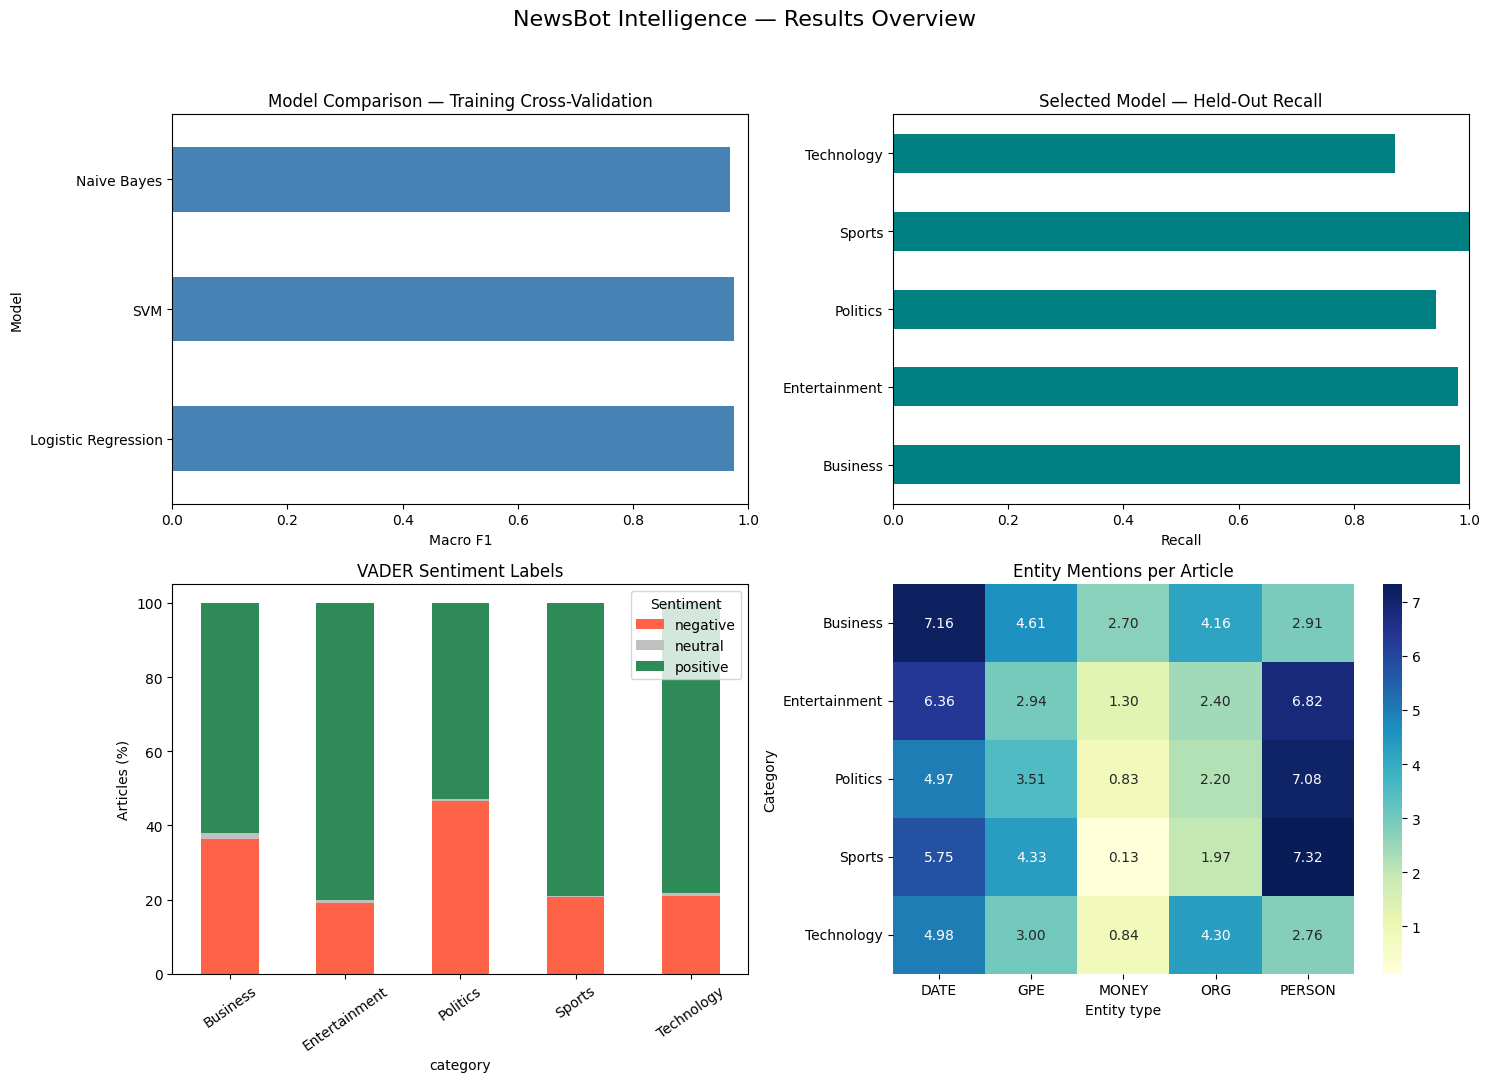

,articles,median_words,test_recall,positive_label_pct,person_mentions_per_article,org_mentions_per_article,money_mentions_per_article,mean_sentence_tokens
Business,335,304.0,0.985,62.090,2.907,4.155,2.704,22.024
Entertainment,263,271.0,0.981,80.228,6.821,2.403,1.304,21.654
Politics,266,445.0,0.943,53.008,7.083,2.195,0.835,22.448
Sports,342,296.5,1.000,78.947,7.322,1.968,0.126,19.662
Technology,234,461.5,0.872,78.205,2.761,4.303,0.838,21.807


Selected classifier: Logistic Regression
Held-out accuracy: 96.18%
Held-out macro F1: 0.9598
Misclassified test articles: 11

Interpretation limits:
- Test performance describes this BBC split, not all future news.
- Sentiment and entities are automated estimates requiring review.
- Category averages do not describe every individual article.


In [ ]:
def create_comprehensive_analysis():
    """Summarize classification and linguistic findings in one dashboard."""

    fig, axes = plt.subplots(2, 2, figsize=(15, 11))

    # 1. Compare model performance measured during cross-validation.
    # These scores were used for selection, before test evaluation.
    model_scores = comparison_df.set_index("Model")["CV Macro F1"]
    model_scores.plot.barh(ax=axes[0, 0], color="steelblue")
    axes[0, 0].set_title("Model Comparison — Training Cross-Validation")
    axes[0, 0].set_xlabel("Macro F1")
    axes[0, 0].set_xlim(0, 1)

    # 2. Show category-level recall on the held-out test articles.
    # Recall measures the fraction of a category's articles found correctly.
    test_recall = report_df.loc[best_model.classes_, "recall"]
    test_recall.plot.barh(ax=axes[0, 1], color="teal")
    axes[0, 1].set_title("Selected Model — Held-Out Recall")
    axes[0, 1].set_xlabel("Recall")
    axes[0, 1].set_xlim(0, 1)

    # 3. Compare textual sentiment labels across categories.
    sentiment_dist_pct.plot.bar(
        stacked=True,
        color=["tomato", "silver", "seagreen"],
        ax=axes[1, 0]
    )
    axes[1, 0].set_title("VADER Sentiment Labels")
    axes[1, 0].set_ylabel("Articles (%)")
    axes[1, 0].tick_params(axis="x", rotation=35)
    axes[1, 0].legend(title="Sentiment")

    # 4. Compare entity mentions per article across categories.
    sns.heatmap(
        entity_rates,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        ax=axes[1, 1]
    )
    axes[1, 1].set_title("Entity Mentions per Article")
    axes[1, 1].set_xlabel("Entity type")
    axes[1, 1].set_ylabel("Category")

    # Save the combined dashboard for the README and presentation.
    fig.suptitle("NewsBot Intelligence — Results Overview", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(
        output_dir / "newsbot_dashboard.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

    # Build a compact table connecting results from several modules.
    # Category names align the rows across independently computed tables.
    summary = pd.DataFrame({
        "articles": df.groupby("category").size(),
        "median_words": df.groupby("category")["word_count"].median(),
        "test_recall": test_recall,
        "positive_label_pct": sentiment_dist_pct["positive"],
        "person_mentions_per_article": entity_rates["PERSON"],
        "org_mentions_per_article": entity_rates["ORG"],
        "money_mentions_per_article": entity_rates["MONEY"],
        "mean_sentence_tokens": syntax_summary["mean_sentence_length"]
    })

    summary.to_csv(output_dir / "integrated_category_summary.csv")
    display(summary.round(3))

    # Report actual evaluation results rather than hard-coded claims.
    print(f"Selected classifier: {best_model_name}")
    print(f"Held-out accuracy: {test_accuracy:.2%}")
    print(f"Held-out macro F1: {test_macro_f1:.4f}")
    print(f"Misclassified test articles: {len(errors_df)}")
    print("\nInterpretation limits:")
    print("- Test performance describes this BBC split, not all future news.")
    print("- Sentiment and entities are automated estimates requiring review.")
    print("- Category averages do not describe every individual article.")

    return summary


# Generate the dashboard and retain its summary table.
comprehensive_summary = create_comprehensive_analysis()

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates a real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [ ]:
class NewsBotIntelligenceSystem:
    """Combine classification, entities, sentiment, and linguistic analysis."""

    def __init__(self, classifier_pipeline, nlp_model):
        # Keep the fitted TF-IDF and classifier together.
        # This ensures new articles use the same features as training.
        self.classifier = classifier_pipeline
        self.nlp = nlp_model

    def process_article(self, title, content):
        """Analyze one new article without retraining the model."""

        # Reject invalid or empty article content with a clear message.
        if not isinstance(content, str) or not content.strip():
            raise ValueError("Please provide nonempty article text.")
        if not isinstance(title, str):
            raise ValueError("The title must be a string; use '' if absent.")

        # Combine the optional title and body.
        # If the body already contains the title, pass an empty title.
        full_text = f"{title.strip()}\n{content.strip()}".strip()

        # Apply exactly the preprocessing used for classifier training.
        processed_text = preprocess_text(full_text)
        if not processed_text:
            raise ValueError("No usable words remained after preprocessing.")

        # Use the fitted pipeline to predict the article category.
        category = self.classifier.predict([processed_text])[0]
        probabilities = self.classifier.predict_proba([processed_text])[0]
        class_probs = dict(zip(
            self.classifier.classes_,
            [float(value) for value in probabilities]
        ))

        # Process the original text once for the linguistic components.
        doc = self.nlp(full_text)
        entities = entities_from_doc(doc)
        sentiment = analyze_sentiment(full_text)
        emotion_rates, emotion_matches = analyze_emotion_cues(doc)
        relationships = extract_svo(doc)

        # Calculate grammatical proportions for this new article.
        tokens = [
            token for token in doc
            if not token.is_space and not token.is_punct
        ]
        pos_counts = Counter(token.pos_ for token in tokens)
        pos_proportions = {
            tag: count / max(len(tokens), 1)
            for tag, count in pos_counts.items()
        }

        # Show the strongest TF-IDF terms using the selected model's
        # vocabulary, rather than the earlier exploratory vectorizer.
        vectorizer = self.classifier.named_steps["tfidf"]
        features = vectorizer.transform([processed_text])
        vocabulary = vectorizer.get_feature_names_out()

        ranked_terms = sorted(
            zip(features.indices, features.data),
            key=lambda item: item[1],
            reverse=True
        )[:10]

        # Produce descriptive summaries without treating predictions as facts.
        insights = [
            f"Suggested news category: {category}.",
            f"VADER textual tone: {sentiment['sentiment_label']}.",
            f"Detected {len(entities)} required-type entity mentions."
        ]

        # Return structured results for display or later application use.
        return {
            "title": title,
            "content": content,
            "predicted_category": category,
            "category_confidence": class_probs[category],
            "category_probabilities": class_probs,
            "entities": entities,
            "sentiment": sentiment,
            "emotion_cues_per_1000_tokens": emotion_rates,
            "emotion_matches": emotion_matches,
            "pos_proportions": pos_proportions,
            "sentence_count": len(list(doc.sents)),
            "candidate_relationships": relationships,
            "top_tfidf_terms": [
                {"term": vocabulary[index], "score": float(score)}
                for index, score in ranked_terms
            ],
            "insights": insights
        }


# Initialize NewsBot with the model selected through cross-validation.
newsbot = NewsBotIntelligenceSystem(best_model, nlp)

print("NewsBot is ready to analyze new articles.")
print("Supported categories:", ", ".join(best_model.classes_))
print("Category probabilities are model estimates, not guarantees.")

NewsBot is ready to analyze new articles.
Supported categories: Business, Entertainment, Politics, Sports, Technology
Category probabilities are model estimates, not guarantees.


In [ ]:
# Test the complete system
import json

# These fictional examples were created for a functional demonstration.
# They are not real reporting or part of the BBC training dataset.
# Their results do not establish accuracy on real-world news.
test_articles = [
    {
        "title": "Football club celebrates championship victory",
        "content": (
            "London football club Riverside United won the league "
            "championship on Saturday after defeating their rivals 3-1. "
            "Captain Daniel Reed scored two goals in the final match. "
            "The coach praised the players for their teamwork and said "
            "supporters were thrilled with the result. Thousands of fans "
            "celebrated outside the stadium. The team will begin training "
            "next month ahead of the new season."
        )
    },
    {
        "title": "Software company introduces a security platform",
        "content": (
            "Northstar Software introduced a new computer security platform "
            "in Boston on Monday. The company said its software detects "
            "suspicious network traffic and helps users protect their data. "
            "Engineer Maya Chen demonstrated the application and explained "
            "how administrators can install updates across multiple devices. "
            "The company invested $5 million in development. Independent "
            "testing has not yet established how well the system performs "
            "against unfamiliar threats."
        )
    }
]

demo_results = []

for article in test_articles:
    # Run every component through the integrated NewsBot interface.
    result = newsbot.process_article(
        article["title"], article["content"]
    )
    demo_results.append(result)

    print("\n" + "=" * 70)
    print("FICTIONAL DEMONSTRATION:", result["title"])
    print("Predicted category:", result["predicted_category"])
    print(
        "Model probability for that category:",
        f"{result['category_confidence']:.2%}"
    )
    print("Sentiment:", result["sentiment"]["sentiment_label"])
    print("VADER compound score:", result["sentiment"]["compound"])
    print("Emotion keyword matches:", result["emotion_matches"])

    # Display predicted entities and extracted relationships for inspection.
    print("\nNamed entities:")
    display(pd.DataFrame(
        result["entities"],
        columns=["text", "label", "start", "end", "description"]
    ))

    print("\nCandidate subject–verb–object relationships:")
    display(pd.DataFrame(
        result["candidate_relationships"],
        columns=["subject", "verb", "object", "negated", "sentence"]
    ))

    print("\nHighest-scoring TF-IDF terms:")
    display(pd.DataFrame(result["top_tfidf_terms"]))

# Verify that empty input produces a helpful error instead of a prediction.
try:
    newsbot.process_article("", "")
except ValueError as error:
    print("\nEmpty-input check passed:", error)
else:
    raise AssertionError("Empty content should raise ValueError.")

# Save the complete demonstration results for documentation.
with open(output_dir / "newsbot_demo_results.json", "w", encoding="utf-8") as file:
    json.dump(demo_results, file, indent=2, ensure_ascii=False)

print("\nDemonstration results saved.")


FICTIONAL DEMONSTRATION: Football club celebrates championship victory
Predicted category: Sports
Model probability for that category: 91.90%
Sentiment: positive
VADER compound score: 0.9779
Emotion keyword matches: {'joy': {'celebrate': 2}, 'sadness': {}, 'anger': {}, 'fear': {}, 'surprise': {}, 'trust': {}}

Named entities:


,text,label,start,end,description
0,London,GPE,46,52,"Countries, cities, states"
1,Riverside United,PERSON,67,83,"People, including fictional"
2,Saturday,DATE,115,123,Absolute or relative dates or periods
3,Daniel Reed,PERSON,166,177,"People, including fictional"
4,next month,DATE,394,404,Absolute or relative dates or periods
5,the new season,DATE,414,428,Absolute or relative dates or periods



Candidate subject–verb–object relationships:


,subject,verb,object,negated,sentence
0,championship victory\nLondon football club Riv...,win,the league championship,False,Football club celebrates championship victory\...
1,Captain Daniel Reed,score,two goals,False,Captain Daniel Reed scored two goals in the fi...
2,The coach,praise,the players,False,The coach praised the players for their teamwo...



Highest-scoring TF-IDF terms:


...


Candidate subject–verb–object relationships:


,subject,verb,object,negated,sentence
0,Software company,introduce,a security platform,False,Software company introduces a security platfor...
1,Northstar Software,introduce,a new computer security platform,False,Software company introduces a security platfor...
2,users,protect,their data,False,The company said its software detects suspicio...
3,Engineer Maya Chen,demonstrate,the application,False,Engineer Maya Chen demonstrated the applicatio...
4,administrators,install,updates,False,Engineer Maya Chen demonstrated the applicatio...
5,The company,invest,million,False,The company invested $5 million in development.



Highest-scoring TF-IDF terms:


,term,score
0,platform,0.303002
1,software,0.297584
2,security,0.213016
3,boston,0.211115
4,engineer,0.211115
5,install,0.211115
6,multiple,0.211115
7,demonstrated,0.207614
8,testing,0.196222
9,update,0.191625



Empty-input check passed: Please provide nonempty article text.

Demonstration results saved.


In [ ]:
import shutil
from google.colab import files

# Compress the charts, tables, and demo results into one ZIP file.
archive_path = shutil.make_archive(
    "/content/newsbot_outputs",
    "zip",
    root_dir="/content",
    base_dir="outputs"
)

# Download the ZIP to your computer.
files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Project Results and Interpretation

### Classification Performance

Cross-validation selected Logistic Regression with unigram TF-IDF
features and sublinear term frequency.

| Model | Cross-validation macro F1 |
|---|---:|
| Logistic Regression | 0.9749 |
| SVM | 0.9746 |
| Naive Bayes | 0.9685 |

Logistic Regression and SVM performed similarly. Logistic Regression
had the highest observed mean macro F1 and required less tuning time
in our session. The small score difference does not establish a
statistically significant advantage.

On 288 held-out articles, the selected model achieved:

- Accuracy: 96.18%
- Macro F1: 0.9598
- Correct predictions: 277
- Incorrect predictions: 11

Technology had the lowest recall, 87.23%. Some gaming articles were
classified as Sports, while technology-company stories were classified
as Business. These errors illustrate overlapping category vocabulary.

### Findings Across NLP Modules

- Technology articles had the highest median length: 461.5 words.
- Business had the highest average number-token proportion: 3.89%.
- Politics had the highest verb proportion: 13.68%, and the highest
  average sentence length: 22.45 tokens.
- VADER labeled 80.23% of Entertainment articles positive.
  Politics had the highest negative-label percentage, 46.62%.
- Business had the most MONEY mentions per article, 2.70.
  Sports had the most PERSON mentions, 7.32.
  Technology had the most ORG mentions, 4.30.
- The exploratory emotion lexicon found the highest joy-cue rate in
  Sports and the highest fear-cue rate in Politics. These are keyword
  patterns, not validated emotion labels.
- Entity co-occurrence revealed unresolved aliases: “Tony Blair” and
  “Blair” appeared together in 51 articles.

### Business Implications

The classifier could support initial article routing, with human
review for ambiguous stories. Entity extraction could help analysts
find coverage mentioning organizations, people, and locations.
Category-level summaries provide starting points for further review.

The project has not measured operational time savings. Sentiment
scores should not be interpreted as public opinion, author intent,
or evidence of media bias.

### Limitations

1. Results describe one split of this historical BBC dataset.
   They do not establish performance on current news or other publishers.
2. Only five categories are supported. An article outside these categories
   will still receive one of the available labels.
3. Exact duplicate texts were removed, but near-duplicate stories may remain.
4. The supplied text is lowercase, which can reduce grammatical tagging
   and named entity recognition accuracy.
5. Starter preprocessing can merge hyphenated words and uses basic
   noun-default lemmatization. It does not fully handle HTML entities
   or contractions.
6. VADER and the small emotion lexicon were not evaluated against
   human-labeled sentiment or emotion data.
7. Subject–verb–object extraction handles only simple active patterns.
   Parser mistakes, pronouns, passive voice, and quoted claims require review.
8. Co-occurrence means two names appear in the same article.
   It does not establish a real-world relationship or resolve aliases.
9. Model probabilities are estimates, not guarantees of correctness.
10. Fictional demonstration inputs test functionality, not generalization
    to real unseen news.

### Future Improvements

- Evaluate on recent, independently sourced articles.
- Detect near-duplicate stories before splitting data.
- Compare TF-IDF against combined linguistic features using training-only
  cross-validation.
- Improve preprocessing and assess the changes without repeatedly tuning
  against the current test set.
- Evaluate a documented emotion lexicon and manually review a sample
  of sentiment, entity, and relationship predictions.
- Add entity alias resolution and an evaluated human-review workflow.

### Sources and Acknowledgments

- Instructor-provided NewsBot Intelligence System starter notebook
  and ITAI 2373 assignment instructions.
- BBC News Classification dataset:
  https://www.kaggle.com/competitions/learn-ai-bbc/data
- scikit-learn documentation:
  https://scikit-learn.org/stable/
- spaCy documentation:
  https://spacy.io/usage
- NLTK documentation:
  https://www.nltk.org/
- VADER project:
  https://github.com/cjhutto/vaderSentiment
- OpenAI ChatGPT/Codex assistance with code adaptation, debugging,
  explanations, and documentation.

The emotion keyword list is an illustrative project baseline generated
with AI assistance; it is not an externally validated lexicon.
The two demonstration articles are fictional examples.